# DengAI — locked report window, controlled model comparison

**Goal.** Forecast weekly dengue cases (`total_cases`) in San Juan (`sj`) and Iquitos (`iq`) for the test period that follows the training data (260 and 156 weeks).

**Approach.** Nine model families (Poisson, Negative Binomial and their ridge versions, random forest, LightGBM, XGBoost) are compared under a **controlled comparison**: for a given feature set and architecture every family receives the same input columns, so a difference between rows is a difference between models. Everything is validated by time, never at random, and the data are split once before any model is fitted:

```
city weeks:  |---------------- development region ----------------|--- report window (locked) ---|
             exploration uses ONLY these rows                      last 260 (sj) / 156 (iq) weeks, same as the test period lengths
```

**Notebook map**

| Section | What it does | Main objects |
|---|---|---|
| Setup | imports, constants (`CONFIG`) | all-caps names |
| 1 | load and validate the raw files | `train_features`, `train_labels`, `test_features` |
| 2 | cleaning, causal imputation, features | `weather`, `training_all`, `SEASON_COLUMNS`, `HISTORY_COLUMNS` |
| 3 | locked split | `dev`, `report` |
| 4 | validation folds inside `dev` | `fitting_rows`, `fold_data`, `annual_splits`, `long_splits` |
| 5 | model code (GLMs, ridge, designs, trees) | `fit_candidate`, `predict_candidate` |
| 6 | baselines | `baseline_forecast`, `BASELINE_ANNUAL`, `BASELINE_LONG` |
| 7 | run all candidates on all folds | `evaluate_splits`, `cv_predictions`, `fit_log` |
| 8 | scoring and the controlled comparison | `summarize`, `comparison` |
| 9 | hyperparameter tuning (development folds only) | `cv_score`, `nb_tuning*`, `lgbm_tuning` |
| 10 | final model scored once on the report window | `FINAL`, `report_pred` |


**Validation inside the development region (per city):** three annual folds (the last three 52-week blocks of the development region, expanding history) and one development long fold (the last 104 development weeks in one pass). Pooled fits use both cities' development rows dated before the target city's cutoff.

In [1]:
from pathlib import Path
import platform
import warnings
from typing import NamedTuple
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
import statsmodels.api as sm
import sklearn
import lightgbm
import xgboost
from IPython.display import display
from scipy.stats import nbinom, poisson
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from threadpoolctl import threadpool_limits

In [2]:
# ---- Paths ----
FOLDER = Path('../data/raw')
if not FOLDER.is_dir() and Path('data/raw').is_dir(): FOLDER = Path('data/raw')

OUTPUT_DIR = Path('locked_window_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---- Data schema ----
KEYS = ['city', 'year', 'weekofyear']     # `year` is a row key only; it is never a model input in this notebook
TARGET = 'total_cases'
CITIES = ['sj', 'iq']
CITY_NAMES = {'sj': 'San Juan', 'iq': 'Iquitos'}

# Validation design (all inside the development region)
N_FOLDS = 3                 # annual folds per city
FOLD_WEEKS = 52             # length of each annual fold
DEV_LONG_WEEKS = 104        # development long fold: last 104 development weeks predicted in one pass
MIN_OTHER_CITY_ROWS = 52    # a pooled fit only includes the other city if it has at least this many fitting rows
N_THREADS = 2
RANDOM_STATE = 42

# Weather handling (causal: only earlier weeks are used)
ABSOLUTE_TEMP_K = ['reanalysis_air_temp_k', 'reanalysis_avg_temp_k', 'reanalysis_dew_point_temp_k',
                   'reanalysis_max_air_temp_k', 'reanalysis_min_air_temp_k']
DROP_DUPLICATE = 'precipitation_amt_mm'   # exact duplicate of reanalysis_sat_precip_amt_mm

# Forward fill up to previous 4 datapoints (week_of_year)
FFILL_LIMIT = 4

# Feature sets (identical for every model family)
N_HARMONICS = 2 # (Phase 1 and 2)

CORE = ['reanalysis_specific_humidity_g_per_kg', 'station_avg_temp_c', 'precip_log1p', 'reanalysis_tdtr_c']

LAG_BLOCKS = {'b1_4': (1, 4), 'b5_8': (5, 8), 'b9_12': (9, 12)}   # mean of weeks t-first ... t-last

WEATHER_SETS = {'seasonal': [],                                    # seasonal curve only
                'no_weather_lag': ['L0'],                          # + current-week weather
                'with_weather_lag': ['L0'] + list(LAG_BLOCKS)}     # + current week and the three 4-week block means

# MAX_HISTORY = 13            # first 13 weeks of each city are history only (12 would suffice)
MAX_HISTORY = 12            # first 12 weeks of each city are history only (omitted from training, since we use lag features)

# Model families
UNPENALISED_GLM_FAMILIES = ['poisson', 'negative_binomial']

RIDGE_LAMBDAS = [0.1, 1.0]                # ridge (L2) penalty strengths, mild and strong; not tuned here
RIDGE_FAMILIES = [f'{f}_ridge_{lam:g}' for f in UNPENALISED_GLM_FAMILIES for lam in RIDGE_LAMBDAS]

GLM_FAMILIES = ['poisson', 'poisson_ridge_0.1', 'poisson_ridge_1', 'negative_binomial', 'negative_binomial_ridge_0.1', 'negative_binomial_ridge_1']
assert set(GLM_FAMILIES) == set(UNPENALISED_GLM_FAMILIES + RIDGE_FAMILIES)

TREE_FAMILIES = ['random_forest', 'lightgbm_mae', 'xgboost_mae']

FAMILIES = GLM_FAMILIES + TREE_FAMILIES
ARCHITECTURES = ['separate', 'pooled']    # pooled = shared coefficients + city intercept (GLMs) / is_iq column (trees)

ALPHA_BOUNDS = (1e-3, 20.0)               # Overdispersion parameter for Negative binomial regression

# ---- Display settings ----
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 220)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False}) #matplotlib display setting

# warnings.filterwarnings('ignore', module='statsmodels') # Deprecation/convergence warning

# Package version
print({'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__, 'statsmodels': statsmodels.__version__,
       'scikit_learn': sklearn.__version__, 'lightgbm': lightgbm.__version__, 'xgboost': xgboost.__version__})

{'python': '3.11.4', 'pandas': '3.1.1', 'numpy': '2.4.6', 'statsmodels': '0.15.0', 'scikit_learn': '1.9.1', 'lightgbm': '4.7.0', 'xgboost': '3.2.0'}


## 1. Load and validate the data
Keys are unique, features and labels join one-to-one, test follows train in each city, test keys match the submission template, targets are non-negative integers. The raw competition files are read from `data/raw` and are not copied into any output.

In [3]:
RAW_FILES = ['dengue_features_train.csv', 'dengue_labels_train.csv', 'dengue_features_test.csv', 'submission_format.csv']

def load_raw_data():
    for name in RAW_FILES:
        if not (FOLDER / name).is_file(): raise FileNotFoundError(f'Update FOLDER: missing {name}')

    train_features = pd.read_csv(FOLDER / RAW_FILES[0], parse_dates=['week_start_date']) # Parse and convert to pandas datetime64 type (YYYY-MM-DD)
    train_labels = pd.read_csv(FOLDER / RAW_FILES[1])
    test_features = pd.read_csv(FOLDER / RAW_FILES[2], parse_dates=['week_start_date'])
    submission_format = pd.read_csv(FOLDER / RAW_FILES[3])
    return train_features, train_labels, test_features, submission_format

def validate_raw_data(train_features, train_labels, test_features, submission_format):
    """Assertions only (plus the feature/label join, returned for a quick look)."""
    # KEYS = ['city', 'year', 'weekofyear']
    # Checks every cell in the KEYS columns for missing values, or duplicate
    for frame in [train_features, train_labels, test_features, submission_format]:
        assert not frame[KEYS].isna().any().any() and not frame.duplicated(KEYS).any()

    # CITIES = ['sj', 'iq']
    assert set(train_features.columns) == set(test_features.columns)
    assert set(train_features.city) == set(test_features.city) == set(CITIES)

    # TARGET = 'total_cases'
    joined = train_features.merge(train_labels, on=KEYS, how='outer', validate='one_to_one', indicator=True)
    assert joined['_merge'].eq('both').all() # Every single training feature row has a matching label row
    assert np.isfinite(train_labels[TARGET]).all() and train_labels[TARGET].ge(0).all() and train_labels[TARGET].mod(1).eq(0).all()
    assert train_features[KEYS].merge(test_features[KEYS], on=KEYS).empty # Zero-overlap (anti-leakage) check

    check = test_features[KEYS].merge(submission_format[KEYS], on=KEYS, how='outer', validate='one_to_one', indicator=True)
    assert check['_merge'].eq('both').all()

    # No temporal leakage in train/test set
    for city in CITIES:
        assert (train_features.loc[train_features.city.eq(city), 'week_start_date'].max()
                < test_features.loc[test_features.city.eq(city), 'week_start_date'].min())
    return joined

train_features, train_labels, test_features, submission_format = load_raw_data()
joined = validate_raw_data(train_features, train_labels, test_features, submission_format)

test_weights = test_features.city.value_counts(normalize=True).reindex(CITIES)
test_counts = test_features.city.value_counts().reindex(CITIES)

display(train_features.groupby('city').agg(rows=('city', 'size'), start=('week_start_date', 'min'), end=('week_start_date', 'max')))
print('Test city weights:', test_weights.to_dict(), '| test rows:', test_counts.to_dict())

def test_mix(by_city):
    """Weighted average of a per-city quantity with the test set's city weights (sj 0.625, iq 0.375)."""
    return sum(by_city[c] * test_weights[c] for c in CITIES)

,rows,start,end
city,,,
iq,520,2000-07-01,2010-06-25
sj,936,1990-04-30,2008-04-22


Test city weights: {'sj': 0.625, 'iq': 0.375} | test rows: {'sj': 260, 'iq': 156}


In [4]:
joined.head()

,city,year,weekofyear,week_start_date,ndvi_ne,ndvi_nw,ndvi_se,ndvi_sw,precipitation_amt_mm,reanalysis_air_temp_k,reanalysis_avg_temp_k,reanalysis_dew_point_temp_k,reanalysis_max_air_temp_k,reanalysis_min_air_temp_k,reanalysis_precip_amt_kg_per_m2,reanalysis_relative_humidity_percent,reanalysis_sat_precip_amt_mm,reanalysis_specific_humidity_g_per_kg,reanalysis_tdtr_k,station_avg_temp_c,station_diur_temp_rng_c,station_max_temp_c,station_min_temp_c,station_precip_mm,total_cases,_merge
0,iq,2000,26,2000-07-01,0.193,0.132,0.341,0.247,25.410,296.740,298.450,295.184,307.300,293.100,43.190,92.419,25.410,16.651,8.929,26.400,10.775,32.500,20.700,3.000,0,both
1,iq,2000,27,2000-07-08,0.217,0.276,0.289,0.242,60.610,296.634,298.429,295.359,306.600,291.100,46.000,93.581,60.610,16.863,10.314,26.900,11.567,34.000,20.800,55.600,0,both
2,iq,2000,28,2000-07-15,0.177,0.173,0.204,0.128,55.520,296.416,297.393,295.623,304.500,292.600,64.770,95.849,55.520,17.120,7.386,26.800,11.467,33.000,20.700,38.100,0,both
3,iq,2000,29,2000-07-22,0.228,0.145,0.254,0.200,5.600,295.357,296.229,292.797,303.600,288.600,23.960,87.234,5.600,14.431,9.114,25.767,10.533,31.500,14.700,30.000,0,both
4,iq,2000,30,2000-07-29,0.329,0.322,0.254,0.361,62.760,296.433,297.636,293.957,307.000,291.500,31.800,88.161,62.760,15.444,9.500,26.600,11.480,33.300,19.100,4.000,0,both


## 2. Cleaning, causal imputation and features
- Kelvin temperatures become Celsius; the duplicate rainfall column is dropped.
- Missing weather is filled **using only earlier weeks** (carry forward at most 4 weeks, then the city's expanding median of earlier values). This runs once on the chronological table and never looks forward, so it is valid in every fold and cannot leak the locked window into earlier rows.
- `precip_log1p = log(1 + rainfall)` compresses the long right tail of weekly rainfall.
- Two annual harmonics (`season_sin_k`, `season_cos_k`, k = 1, 2) give the seasonal curve.
- For each of the four core weather variables: the current week (`__L0`) and the means of three non-overlapping 4-week blocks before it, `__b1_4` (weeks t−1…t−4), `__b5_8` (t−5…t−8) and `__b9_12` (t−9…t−12). The blocks do not overlap, so each describes a different stretch of the past, and together they cover the 1–3 month delay between weather and reported cases.
- Every lag and block mean is built by row within city, uses only earlier rows, and needs a complete window (`min_periods` = window length).
- **No `year` column is created or used.**

In [5]:
# ABSOLUTE_TEMP_K = ['reanalysis_air_temp_k', 'reanalysis_avg_temp_k', 'reanalysis_dew_point_temp_k',
#                    'reanalysis_max_air_temp_k', 'reanalysis_min_air_temp_k']

# DROP_DUPLICATE = 'precipitation_amt_mm'

def clean_features(df):
    df = df.copy()
    df[ABSOLUTE_TEMP_K] = df[ABSOLUTE_TEMP_K] - 273.15
    df = df.rename(columns={c: c[:-2] + '_c' for c in ABSOLUTE_TEMP_K + ['reanalysis_tdtr_k']})
    return df.drop(columns=DROP_DUPLICATE)

for _f in (train_features, test_features):
    assert _f[DROP_DUPLICATE].equals(_f['reanalysis_sat_precip_amt_mm'])

train_features, test_features = clean_features(train_features), clean_features(test_features)

# KEYS = ['city', 'year', 'weekofyear']
WEATHER_FEATURES = [c for c in train_features if c not in KEYS + ['week_start_date']]
assert len(WEATHER_FEATURES) == 19

# No duplicate timestamp for a given city
weather = pd.concat([train_features.assign(_split='train'), test_features.assign(_split='test')],
                    ignore_index=True).sort_values(['city', 'week_start_date']).reset_index(drop=True)
assert not weather.duplicated(['city', 'week_start_date']).any()

In [6]:
def impute_weather(weather):
    """Causal imputation, using only earlier weeks: forward fill (at most FFILL_LIMIT weeks), then the city's expanding median of earlier values."""
    observed = weather[WEATHER_FEATURES].copy()
    past_median = observed.groupby(weather.city).transform(lambda s: s.expanding().median().shift(1)) # Expanding median

    weather[WEATHER_FEATURES] = observed.groupby(weather.city).ffill(limit=FFILL_LIMIT) # FFILL_LIMIT = 4

    n_missing_original = int(observed.isna().sum().sum())
    n_after_ffill = int(weather[WEATHER_FEATURES].isna().sum().sum())
    weather[WEATHER_FEATURES] = weather[WEATHER_FEATURES].fillna(past_median)

    n_still_missing = int(weather[WEATHER_FEATURES].isna().sum().sum())
    print({'missing_weather_cells': n_missing_original, 'filled_by_forward_fill': n_missing_original - n_after_ffill,
           'filled_by_past_median': n_after_ffill - n_still_missing, 'still_missing': n_still_missing})
    return weather

weather = impute_weather(weather)

{'missing_weather_cells': 652, 'filled_by_forward_fill': 591, 'filled_by_past_median': 61, 'still_missing': 0}


In [7]:
def add_seasonal_columns(weather):
    """N_HARMONICS sine/cosine pairs of the day of the year. Returns the new column names."""
    # Cyclical encoding
    phase = 2 * np.pi * (weather.week_start_date.dt.day_of_year - 1) / 365
    season_columns = []
    for k in range(1, N_HARMONICS + 1):
        weather[f'season_sin_{k}'], weather[f'season_cos_{k}'] = np.sin(k * phase), np.cos(k * phase)
        season_columns += [f'season_sin_{k}', f'season_cos_{k}']
    return season_columns

# CORE = ['reanalysis_specific_humidity_g_per_kg', 'station_avg_temp_c', 'precip_log1p', 'reanalysis_tdtr_c']
# LAG_BLOCKS = {'b1_4': (1, 4), 'b5_8': (5, 8), 'b9_12': (9, 12)}   # mean of weeks t-first ... t-last

def add_lag_features(weather):
    """For each core variable: the current week (__L0) and the mean of each lag block, built within city. Returns the new column names."""
    history_columns = []
    for column in CORE:
        weather[f'{column}__L0'] = weather[column]
        history_columns.append(f'{column}__L0')
        for name, (first, last) in LAG_BLOCKS.items():
            width = last - first + 1
            weather[f'{column}__{name}'] = weather.groupby('city')[column].transform(
                lambda s, f=first, w=width: s.shift(f).rolling(w, min_periods=w).mean())
            history_columns.append(f'{column}__{name}')
    return history_columns

weather['precip_log1p'] = np.log1p(weather.reanalysis_sat_precip_amt_mm.clip(lower=0))
SEASON_COLUMNS = add_seasonal_columns(weather)
HISTORY_COLUMNS = add_lag_features(weather)

# The block means are what they claim to be: e.g. b5_8 at week t equals the plain mean of weeks t-5 ... t-8 (checked on one city).
_s = weather.loc[weather.city.eq('sj'), CORE[0]].reset_index(drop=True)
_t = 40
assert np.isclose(weather.loc[weather.city.eq('sj'), f'{CORE[0]}__b5_8'].iloc[_t], _s.iloc[_t - 8:_t - 4].mean())
assert np.isclose(weather.loc[weather.city.eq('sj'), f'{CORE[0]}__b1_4'].iloc[_t], _s.iloc[_t - 4:_t].mean())
assert max(last for _, last in LAG_BLOCKS.values()) <= MAX_HISTORY # MAX_HISTORY = 12

In [8]:
training_all = weather.loc[weather._split.eq('train')].drop(columns='_split').merge(
    train_labels, on=KEYS, how='left', validate='one_to_one').sort_values(['city', 'week_start_date']).reset_index(drop=True)

# Flags which training rows have a complete 12-week history
training_all['_eligible'] = training_all.groupby('city').cumcount().ge(MAX_HISTORY)
assert training_all.loc[training_all._eligible, SEASON_COLUMNS + HISTORY_COLUMNS].notna().all().all()

display(training_all.groupby('city').agg(total_rows=('city', 'size'), fitting_rows=('_eligible', 'sum')))

,total_rows,fitting_rows
city,,
iq,520,508
sj,936,924


### 2.1 Features used, grouped by type
Every model sees some combination of the groups below. The three **feature sets** differ only in which weather groups they include; the seasonal curve is in all of them. The table is generated from the constants in the setup cell, so it always matches the code.

- **Seasonal curve:** annual and twice-yearly sine and cosine of the day of the year. It tells the model where in the year a week falls.
- **Current-week weather (`__L0`):** the value in the forecast week itself, for the four core variables: specific humidity, station average temperature, log rainfall and the diurnal temperature range.
- **Lag blocks (`__b1_4`, `__b5_8`, `__b9_12`):** the mean of the weather over the 4 weeks ending 1, 5 and 9 weeks before the forecast week. Dengue cases follow weather with a delay of one to three months (mosquito breeding, virus incubation and reporting), which these blocks cover.
- **Added by the architecture, not by the feature set:** an intercept for GLMs, and in `pooled` a 0/1 city column (`city_iq` for GLMs, `is_iq` for trees).

,group,n_columns,seasonal,no_weather_lag,with_weather_lag,columns
0,Seasonal curve,4,yes,yes,yes,"season_sin_1, season_cos_1, season_sin_2, season_cos_2"
1,Current-week weather (L0),4,,yes,yes,"reanalysis_specific_humidity_g_per_kg__L0, station_avg_temp_c__L0, precip_log1p__L0, reanalysis_tdtr_c__L0"
2,Lag block: mean of weeks t-1 to t-4 (b1_4),4,,,yes,"reanalysis_specific_humidity_g_per_kg__b1_4, station_avg_temp_c__b1_4, precip_log1p__b1_4, reanalysis_tdtr..."
3,Lag block: mean of weeks t-5 to t-8 (b5_8),4,,,yes,"reanalysis_specific_humidity_g_per_kg__b5_8, station_avg_temp_c__b5_8, precip_log1p__b5_8, reanalysis_tdtr..."
4,Lag block: mean of weeks t-9 to t-12 (b9_12),4,,,yes,"reanalysis_specific_humidity_g_per_kg__b9_12, station_avg_temp_c__b9_12, precip_log1p__b9_12, reanalysis_t..."
5,Total seasonal + weather columns,,4,8,20,


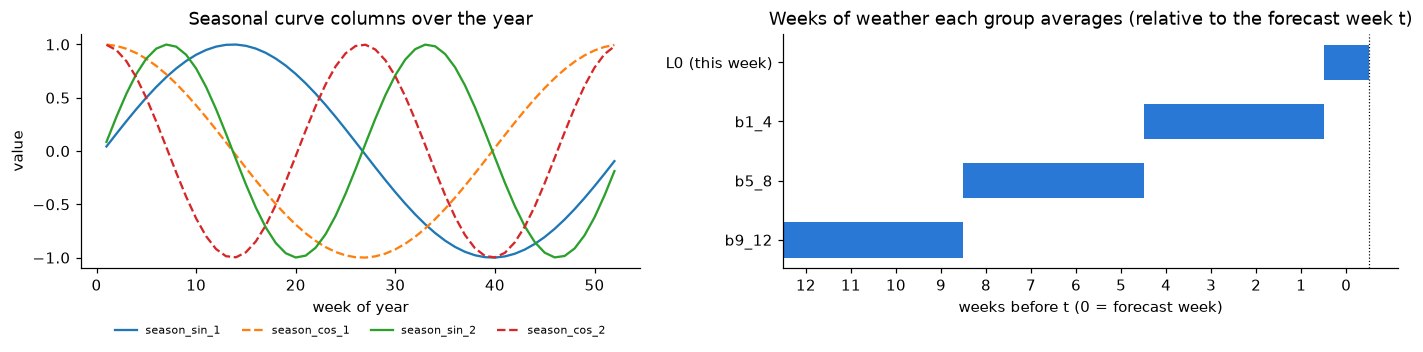

In [9]:
# (group, columns, key in WEATHER_SETS[...] that switches the group on; None = always on)
FEATURE_GROUPS = ([('Seasonal curve', SEASON_COLUMNS, None), ('Current-week weather (L0)', [f'{c}__L0' for c in CORE], 'L0')]
                  + [(f'Lag block: mean of weeks t-{first} to t-{last} ({name})', [f'{c}__{name}' for c in CORE], name)
                     for name, (first, last) in LAG_BLOCKS.items()])
assert {c for _, cols, _ in FEATURE_GROUPS for c in cols} == set(SEASON_COLUMNS + HISTORY_COLUMNS)

def feature_group_table():
    rows = []
    for group, columns, key in FEATURE_GROUPS:
        row = {'group': group, 'n_columns': len(columns)}
        row.update({s: ('yes' if key is None or key in WEATHER_SETS[s] else '') for s in WEATHER_SETS})
        row['columns'] = ', '.join(columns)
        rows.append(row)
    table = pd.DataFrame(rows)
    totals = {'group': 'Total seasonal + weather columns', 'n_columns': '', 'columns': ''}
    totals.update({s: int(table.loc[table[s].eq('yes'), 'n_columns'].sum()) for s in WEATHER_SETS})
    return pd.concat([table, pd.DataFrame([totals])], ignore_index=True)

with pd.option_context('display.max_colwidth', 110): display(feature_group_table())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.4), gridspec_kw={'width_ratios': [1, 1.1]})
weeks = np.arange(1, 53)
phase_demo = 2 * np.pi * ((weeks - 0.5) * 7 - 1) / 365
for k in range(1, N_HARMONICS + 1):
    ax1.plot(weeks, np.sin(k * phase_demo), label=f'season_sin_{k}')
    ax1.plot(weeks, np.cos(k * phase_demo), ls='--', label=f'season_cos_{k}')
ax1.set(title='Seasonal curve columns over the year', xlabel='week of year', ylabel='value'); ax1.legend(fontsize=7, ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.2), frameon=False)

windows = [('L0 (this week)', 0, 0)] + [(f'{name}', first, last) for name, (first, last) in LAG_BLOCKS.items()]
for y, (label, first, last) in enumerate(reversed(windows)):
    ax2.barh(y, last - first + 1, left=-last - 0.5, height=0.6, color='#2a78d6')
ax2.set_yticks(range(len(windows))); ax2.set_yticklabels([w[0] for w in reversed(windows)])
ax2.axvline(0.5, color='k', lw=0.8, ls=':')
ax2.set(title='Weeks of weather each group averages (relative to the forecast week t)', xlabel='weeks before t (0 = forecast week)')
ax2.set_xticks(range(-max(last for _, last in LAG_BLOCKS.values()), 1)); ax2.set_xticklabels([str(abs(int(x))) for x in ax2.get_xticks()])
plt.tight_layout(); plt.show()

## 3. The locked split: development region and report window
Per city, the **last 260 (sj) / 156 (iq) training weeks** (the lengths of the two test periods) become the report window. Every earlier week is the development region. From this point on the notebook works with `dev` only. `report` is kept untouched until Section 10.

Why per city and by position: each city's test period starts right after its own last training week, so the report window should sit at the end of each city's own history.

In [10]:
# CITIES = ['sj', 'iq']

REPORT_WEEKS = {c: int(test_counts[c]) for c in CITIES} # Test city weights: {'sj': 0.625, 'iq': 0.375} | test rows: {'sj': 260, 'iq': 156}

dev_parts, report_parts = [], []
for city in CITIES:
    rows = training_all.loc[training_all.city.eq(city)].sort_values('week_start_date')
    dev_parts.append(rows.iloc[:-REPORT_WEEKS[city]])
    report_parts.append(rows.iloc[-REPORT_WEEKS[city]:])
dev = pd.concat(dev_parts)
report = pd.concat(report_parts)          # Held out: not used until Section 10 (final score)

assert dev.index.isin(report.index).sum() == 0 and len(dev) + len(report) == len(training_all)
for city in CITIES:
    assert dev.loc[dev.city.eq(city), 'week_start_date'].max() < report.loc[report.city.eq(city), 'week_start_date'].min()


split_summary = pd.DataFrame({
    'dev_rows': dev.groupby('city').size(), 'dev_start': dev.groupby('city').week_start_date.min(),
    'dev_end': dev.groupby('city').week_start_date.max(),
    'report_rows': report.groupby('city').size(), 'report_start': report.groupby('city').week_start_date.min(),
    'report_end': report.groupby('city').week_start_date.max()}).reindex(CITIES)
display(split_summary)

REPORT_START = split_summary.report_start.to_dict()
DEV_INDEX = frozenset(dev.index)          # every fit and validation row used below must be in this set
REPORT_INDEX = frozenset(report.index)

,dev_rows,dev_start,dev_end,report_rows,report_start,report_end
city,,,,,,
sj,676,1990-04-30,2003-04-23,260,2003-04-30,2008-04-22
iq,364,2000-07-01,2007-06-25,156,2007-07-02,2010-06-25


## 4. Validation folds inside the development region
For each city: three annual folds (the last three 52-week blocks of the development region) and one development long fold (the last 104 development weeks). A fold's **cutoff** is its first validation week; all fitting rows are dated before it. Pooled fits use both cities' development rows before the target cutoff, **provided the other city has at least 52 fitting rows**.

That last condition matters here: San Juan's development region (1990–2003) mostly predates Iquitos' data (from mid-2000), so for the earliest San Juan folds a "pooled" model has few or no Iquitos rows and becomes effectively a separate model. The split audit shows `n_fit_other_city` for every fold. For Iquitos the pool contains many San Juan rows.

In [11]:
# MIN_OTHER_CITY_ROWS = 52    # a pooled fit only includes the other city if it has at least this many fitting rows

# This helper function selects which rows a model is allowed to train on for a target city,
# depending on whether we are training a single-city model or a pooled multi-city model.
def fitting_rows(available, architecture, city):
    """Rows a candidate may be fitted on: eligible rows before the cutoff (already filtered in 'available')."""
    fit = available.loc[available._eligible]
    if architecture == 'separate':
        return fit.loc[fit.city.eq(city)]
    counts = fit.city.value_counts()
    keep = [c for c in CITIES if c == city or counts.get(c, 0) >= MIN_OTHER_CITY_ROWS] # Only add another city data if other city have accum at least 52 weeks
    return fit.loc[fit.city.isin(keep)]


# N_FOLDS = 3                 # annual folds per city
# FOLD_WEEKS = 52             # length of each annual fold
# DEV_LONG_WEEKS = 104        # development long fold: last 104 development weeks predicted in one pass
# MIN_OTHER_CITY_ROWS = 52    # a pooled fit only includes the other city if it has at least this many fitting rows
# N_THREADS = 2
# RANDOM_STATE = 42

def make_splits(frame):
    annual, devlong, audit = [], [], []
    for city in CITIES:
        rows = frame.loc[frame.city.eq(city)].sort_values('week_start_date')
        n = len(rows)
        for fold in range(1, N_FOLDS + 1):
            stop = n - (N_FOLDS - fold) * FOLD_WEEKS
            valid = rows.iloc[stop - FOLD_WEEKS:stop]
            annual.append({'evaluation': 'annual', 'city': city, 'fold': fold, 'cutoff': valid.week_start_date.min(),
                           'valid_index': valid.index.to_numpy()}) #
        valid = rows.iloc[-DEV_LONG_WEEKS:]
        devlong.append({'evaluation': 'devlong', 'city': city, 'fold': 1, 'cutoff': valid.week_start_date.min(),
                        'valid_index': valid.index.to_numpy()})

    for split in annual + devlong:
        cutoff, city = split['cutoff'], split['city']
        available = frame.loc[frame.week_start_date.lt(cutoff)] # Before cutoff
        valid = frame.loc[split['valid_index']]
        fitting = fitting_rows(available, 'pooled', city)

        assert set(split['valid_index']) <= DEV_INDEX and set(available.index) <= DEV_INDEX
        assert fitting.week_start_date.max() < valid.week_start_date.min() and set(fitting.index).isdisjoint(valid.index)
        assert valid.week_start_date.max() < REPORT_START[city]
        other = [c for c in CITIES if c != city][0]

        audit.append({'evaluation': split['evaluation'], 'target_city': city, 'fold': split['fold'], 'cutoff': cutoff,
                      'history_weeks_target_city': int((available.city == city).sum()),
                      'n_fit_target_city': int(fitting.city.eq(city).sum()),
                      'n_fit_other_city': int(fitting.city.eq(other).sum()), 'n_valid': len(valid),
                      'valid_first': valid.week_start_date.min(), 'valid_last': valid.week_start_date.max()})
    return annual, devlong, pd.DataFrame(audit)

def fold_data(split, frame=None):
    """One split's training history (every row dated before the cutoff) and its validation weeks in time order. `frame` defaults to `dev`."""
    frame = dev if frame is None else frame
    available = frame.loc[frame.week_start_date.lt(split['cutoff'])]
    valid = frame.loc[split['valid_index']].sort_values('week_start_date')
    return available, valid

annual_splits, long_splits, split_audit = make_splits(dev)
display(split_audit)

# split_audit.to_csv(OUTPUT_DIR / 'split_audit.csv', index=False)

,evaluation,target_city,fold,cutoff,history_weeks_target_city,n_fit_target_city,n_fit_other_city,n_valid,valid_first,valid_last
0,annual,sj,1,2000-04-29,520,508,0,52,2000-04-29,2001-04-23
1,annual,sj,2,2001-04-30,572,560,0,52,2001-04-30,2002-04-23
2,annual,sj,3,2002-04-30,624,612,83,52,2002-04-30,2003-04-23
3,annual,iq,1,2004-07-01,208,196,664,52,2004-07-01,2005-06-25
4,annual,iq,2,2005-07-02,260,248,664,52,2005-07-02,2006-06-25
5,annual,iq,3,2006-07-02,312,300,664,52,2006-07-02,2007-06-25
6,devlong,sj,1,2001-04-30,572,560,0,104,2001-04-30,2003-04-23
7,devlong,iq,1,2005-07-02,260,248,664,104,2005-07-02,2007-06-25


## 5. Model code
One interface for every candidate: `fit_candidate(...)` and `predict_candidate(...)`.

**GLMs (`statsmodels`).**
- *Poisson*: `sm.GLM(..., Poisson())`.
- *Negative Binomial (NB2)*, variance `μ + α·μ²`: a Poisson fit gives `μ`; `α` is then set by moments, `α = Σ((y−μ)² − y) / Σμ²` (clipped to `ALPHA_BOUNDS`), and the NB GLM is fitted once with that `α`. A fit whose `α` ends at the edge of the range is flagged.
- *Solver fallback.* IRLS first; if it reports non-convergence, BFGS and then L-BFGS (started at the IRLS solution). The solver used and any non-convergence are recorded.
- *Ridge versions* (`poisson_ridge_0.1`, `poisson_ridge_1`, `negative_binomial_ridge_0.1`, `negative_binomial_ridge_1`): `GLM.fit_regularized(alpha=weights, L1_wt=0)`, minimising `−loglik/n + λ/2 · Σ β²`. Intercepts and the city indicator are not penalised; the standardised weather columns and the seasonal columns are. NB ridge uses the same moment formula on the penalised fit (refreshed three times). λ is not tuned.
- *Ridge convergence.* With `L1_wt=0`, statsmodels uses a separate ridge routine (scipy BFGS) that returns no convergence flag, so a ridge fit counts as converged if its coefficients are finite. Any statsmodels convergence warning is left visible.
- *Point prediction.* `median` (`poisson.ppf` / `nbinom.ppf` at 0.5) minimises absolute error and is the **scoring default for GLMs**; the mean `μ` is stored beside it.
- *Design.* The weather columns are standardised **within city using the fitting rows only**; the seasonal columns are left as they are (already between −1 and 1). `separate`: one model per city. `pooled`: shared coefficients plus a city intercept, one shared `α`.

**Trees** (no scaling needed; `pooled` adds an `is_iq` column; prediction = model output):
- *Random forest*: 300 trees, `min_samples_leaf=5`, all features per split.
- *LightGBM (MAE)*: L1 objective, 200 trees, learning rate 0.05, 7 leaves, `min_child_samples=20`, L2 leaf penalty 1.
- *XGBoost (MAE)*: `reg:absoluteerror`, set up to mirror the LightGBM settings so the two differ by library rather than by settings: 200 trees, learning rate 0.05, leaf-wise growth (`grow_policy='lossguide'`) with at most 7 leaves and no depth limit, `min_child_weight=20` (the absolute-error hessian is 1 per row, so this is at least 20 rows per leaf), `reg_lambda=1`, histogram method.

Feature-set labels are the weather-set names: `seasonal`, `no_weather_lag`, `with_weather_lag`.

### 5.1 Poisson and Negative Binomial GLMs
Both are `statsmodels` GLMs with a log link: Poisson (variance = mean) and NB2 (variance = `μ + α·μ²`, which allows the extra spread real case counts show). Each fitter returns a `GLMFit` with the coefficients, `α` and convergence information.

In [12]:
class GLMFit(NamedTuple):
    """What every GLM fitter returns."""
    params: np.ndarray
    alpha: float            # NaN for Poisson
    converged: bool
    at_bound: bool          # alpha at the edge of ALPHA_BOUNDS
    search_failures: int    # always 0 now (kept so the fit log keeps its columns)
    solver: str

def nb_loglik(y, mu, alpha):
    return nbinom.logpmf(y, 1.0 / alpha, 1.0 / (1.0 + alpha * mu))

def robust_glm_fit(model, start_params=None):
    """IRLS first; if it does not converge, BFGS then L-BFGS started from the IRLS solution. Returns (result, converged, solver)."""
    result = model.fit(start_params=start_params, maxiter=200)
    if result.converged and np.all(np.isfinite(result.params)): return result, True, 'irls'
    for method in ('bfgs', 'lbfgs'):
        try:
            alt = model.fit(start_params=np.asarray(result.params), method=method, maxiter=5000, disp=0)
        except (ValueError, FloatingPointError, np.linalg.LinAlgError):
            continue
        if bool(alt.mle_retvals['converged']) and np.all(np.isfinite(alt.params)): return alt, True, method
    return result, False, 'irls'

def fit_poisson(X, y):
    result, converged, solver = robust_glm_fit(sm.GLM(y, X, family=sm.families.Poisson()))
    return GLMFit(np.asarray(result.params), np.nan, converged, False, 0, solver)

# ALPHA_BOUNDS = (1e-3, 20.0)               # Overdispersion parameter for Negative binomial regression

def moment_alpha(y, mu):
    """NB2 dispersion by moments: E[(y-mu)^2] = mu + alpha*mu^2, so alpha = sum((y-mu)^2 - y) / sum(mu^2)."""
    return float(np.clip(np.sum((y - mu) ** 2 - y) / np.sum(mu ** 2), *ALPHA_BOUNDS))

def alpha_hits_bound(alpha):
    return bool(alpha <= ALPHA_BOUNDS[0] * 1.01 or alpha >= ALPHA_BOUNDS[1] * 0.99) # Alpha hit boundary?

def fit_negative_binomial(X, y):
    """Poisson fit gives mu, alpha comes from the moment formula, then a NB GLM is fitted with that alpha."""
    poisson_fit = sm.GLM(y, X, family=sm.families.Poisson()).fit(maxiter=200)
    alpha = moment_alpha(y, np.asarray(poisson_fit.fittedvalues))
    result, converged, solver = robust_glm_fit(sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=alpha)),
                                               start_params=np.asarray(poisson_fit.params))
    return GLMFit(np.asarray(result.params), alpha, converged, alpha_hits_bound(alpha), 0, solver)

### 5.2 Ridge (L2) versions
The ridge versions add an L2 penalty to the same loss, so correlated lag columns cannot produce large opposite coefficients. The intercept and the city indicator are not penalised.

In [13]:
UNPENALISED_COLUMNS = ('const', 'city_iq')

def penalty_weights(lam, columns):
    return lam * np.array([0.0 if c in UNPENALISED_COLUMNS else 1.0 for c in columns]) #lambda not applied ti intercept and city_iq indicator term

def fit_ridge(X, y, base_family, lam, columns, fixed_alpha=None):
    """Ridge (L2) GLM: minimises -loglik/n + lam/2 * sum(beta^2) over every coefficient except intercepts and the city indicator."""
    weights = penalty_weights(lam, columns)
    # L1_wt=0 makes statsmodels use its ridge routine (scipy BFGS), which returns no convergence flag,
    # so 'converged' below only means the coefficients are finite.
    params = np.asarray(sm.GLM(y, X, family=sm.families.Poisson()).fit_regularized(alpha=weights, L1_wt=0.0).params)
    alpha = np.nan
    if base_family == 'negative_binomial':
        # alpha by moments from the current penalised fit, then refit (3 passes); with `fixed_alpha` (tuning) alpha is set and one pass is enough
        for _ in range(1 if fixed_alpha is not None else 3):
            mu = np.exp(np.clip(X @ params, -30, 30)) # Clip
            alpha = float(fixed_alpha) if fixed_alpha is not None else moment_alpha(y, mu)
            params = np.asarray(sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=alpha)).fit_regularized(
                alpha=weights, L1_wt=0.0, start_params=params).params)

    converged = bool(np.all(np.isfinite(params))) # Fitted model parameters are real values (Not NaN or inf)
    at_bound = bool(base_family == 'negative_binomial' and alpha_hits_bound(alpha))
    return GLMFit(params, alpha, converged, at_bound, 0, 'ridge')

### 5.3 Input columns and design matrices
Which columns each model receives. GLMs get an intercept, a city indicator if `pooled`, the seasonal columns as they are, and the weather columns standardised per city. Trees get the same columns unscaled. `features_used` returns the exact list for any candidate.

In [14]:
def weather_columns(weather_set):
    return [f'{column}__{suffix}' for suffix in WEATHER_SETS[weather_set] for column in CORE]

def glm_numeric_columns(feature_set):
    """Numeric (standardised) columns of a GLM design. Seasonal columns and intercepts are added by make_design."""
    return weather_columns(feature_set)

def tree_columns(feature_set):
    return weather_columns(feature_set) + SEASON_COLUMNS

def features_used(family, architecture, feature_set):
    """Exact input columns of a candidate (GLMs include the intercept and, if pooled, the city indicator)."""
    if family in TREE_FAMILIES:
        return tree_columns(feature_set) + (['is_iq'] if architecture == 'pooled' else [])
    return ['const'] + (['city_iq'] if architecture == 'pooled' else []) + SEASON_COLUMNS + glm_numeric_columns(feature_set)

def make_design(rows, architecture, feature_set, cities, stats):
    """GLM design matrix: intercept, (pooled) city indicator, seasonal columns, then the weather columns standardised per city with `stats`."""
    numeric = glm_numeric_columns(feature_set)
    z = pd.DataFrame(index=rows.index, columns=numeric, dtype=float)
    for city in cities:
        mask = rows.city.eq(city)
        mean, sd = stats[city]
        z.loc[mask] = (rows.loc[mask, numeric] - mean) / sd # Standard z-score scaler
    design = {'const': np.ones(len(rows))}

    if architecture == 'pooled':
        for city in cities[1:]: design[f'city_{city}'] = rows.city.eq(city).to_numpy(float)
    elif architecture != 'separate':
        raise ValueError(architecture)

    for c in SEASON_COLUMNS: design[c] = rows[c].to_numpy(float)
    for c in numeric: design[c] = z[c].to_numpy(float)
    return pd.DataFrame(design, index=rows.index)

def tree_matrix(rows, architecture, feature_set):
    X = rows[tree_columns(feature_set)].copy()
    if architecture == 'pooled': X['is_iq'] = rows.city.eq('iq').to_numpy(float) #Intercept
    return X.to_numpy(float)

### 5.4 Tree models
Three tree ensembles with fixed settings: random forest, and LightGBM and XGBoost with an absolute-error loss. LightGBM and XGBoost use matching settings, so a difference between them comes from the library, not the settings.

In [15]:
def make_tree(family, hyper=None):
    if family == 'random_forest':
        return RandomForestRegressor(n_estimators=300, min_samples_leaf=5, max_features=1.0, random_state=RANDOM_STATE, n_jobs=1)
    if family == 'lightgbm_mae':
        settings = dict(objective='l1', n_estimators=200, learning_rate=0.05, num_leaves=7, min_child_samples=20,
                        reg_lambda=1.0, random_state=RANDOM_STATE, n_jobs=1, verbose=-1)
        return LGBMRegressor(**{**settings, **(hyper or {})})   # `hyper` (tuning) overrides the defaults
    if family == 'xgboost_mae':
        return XGBRegressor(objective='reg:absoluteerror', n_estimators=200, learning_rate=0.05, tree_method='hist',
                            grow_policy='lossguide', max_leaves=7, max_depth=0, min_child_weight=20, reg_lambda=1.0,
                            random_state=RANDOM_STATE, n_jobs=1)
    raise ValueError(family)

### 5.5 One interface for every candidate: `fit_candidate` and `predict_candidate`
`fit_candidate` fits one model for one city on the rows before a cutoff. `predict_candidate` returns the median (the point forecast), the mean and the log-likelihood. The table at the end lists the exact inputs of every feature set and architecture.

In [16]:
def fit_candidate(family, architecture, feature_set, available, city, hyper=None):
    hyper = hyper or {}   # tuning only: {'lam', 'alpha'} for NB ridge, LightGBM settings for lightgbm_mae; empty = the defaults used above
    assert 'year' not in features_used(family, architecture, feature_set)

    fit_rows = fitting_rows(available, architecture, city)
    meta = {'n_fit_target_city': int(fit_rows.city.eq(city).sum()), 'n_fit_other_city': int((~fit_rows.city.eq(city)).sum())}

    # Tree-based fit
    if family in TREE_FAMILIES:
        model = make_tree(family, hyper).fit(tree_matrix(fit_rows, architecture, feature_set), fit_rows[TARGET].to_numpy(float))
        return {'kind': 'tree', 'model': model, 'converged': True, 'alpha': np.nan, 'at_bound': False,
                'search_failures': 0, 'solver': 'tree', **meta}

    cities = [c for c in CITIES if c in set(fit_rows.city)]
    assert city in cities

    numeric = glm_numeric_columns(feature_set)
    stats = {}
    for c in cities:
        part = fit_rows.loc[fit_rows.city.eq(c), numeric]
        stats[c] = (part.mean(), part.std().replace(0, 1.0).fillna(1.0))

    X = make_design(fit_rows, architecture, feature_set, cities, stats)
    y = fit_rows[TARGET].to_numpy(float)
    X_values = X.to_numpy(float)

    # GLM + Ridge fit
    if family in RIDGE_FAMILIES:
        base_family, lam = family.rsplit('_ridge_', 1)
        fit = fit_ridge(X_values, y, base_family, hyper.get('lam', float(lam)), list(X.columns), fixed_alpha=hyper.get('alpha'))
    else: # GLM fit
        fitter = fit_poisson if family == 'poisson' else fit_negative_binomial
        fit = fitter(X_values, y)

    return {'kind': 'glm', 'params': fit.params, 'alpha': fit.alpha, 'stats': stats, 'columns': list(X.columns), 'cities': cities,
            'converged': fit.converged, 'at_bound': fit.at_bound, 'search_failures': fit.search_failures, 'solver': fit.solver, **meta}


def predict_candidate(model, family, architecture, feature_set, rows):
    """Returns (primary point prediction, mean prediction or NaN, loglik inputs). GLM primary = median."""

    # Tree model
    if model['kind'] == 'tree':
        point = np.maximum(model['model'].predict(tree_matrix(rows, architecture, feature_set)), 0)
        return point, np.full(len(rows), np.nan), np.full(len(rows), np.nan)

    X = make_design(rows, architecture, feature_set, model['cities'], model['stats'])
    assert list(X.columns) == model['columns']

    mu = np.exp(np.clip(X.to_numpy(float) @ model['params'], -30, 30))
    is_poisson = family.startswith('poisson')

    if is_poisson:
        median = poisson.ppf(0.5, mu) # Take median of poisson output probability distribution
    else:
        median = nbinom.ppf(0.5, 1.0 / model['alpha'], 1.0 / (1.0 + model['alpha'] * mu))

    y = rows[TARGET].to_numpy(float)
    loglik = poisson.logpmf(y, mu) if is_poisson else nb_loglik(y, mu, model['alpha'])

    return median, mu, loglik

# The exact input columns of every (feature set, architecture), the same for every family apart from the GLM intercept/city indicator
inputs = pd.DataFrame([{'feature_set': s, 'architecture': a, 'n_tree_inputs': len(features_used('random_forest', a, s)),
                        'n_glm_coefficients': len(features_used('poisson', a, s)),
                        'weather_columns': ', '.join(weather_columns(s)) or '(none)'}
                       for s in WEATHER_SETS for a in ARCHITECTURES])
with pd.option_context('display.max_colwidth', 200): display(inputs)

,feature_set,architecture,n_tree_inputs,n_glm_coefficients,weather_columns
0,seasonal,separate,4,5,(none)
1,seasonal,pooled,5,6,(none)
2,no_weather_lag,separate,8,9,"reanalysis_specific_humidity_g_per_kg__L0, station_avg_temp_c__L0, precip_log1p__L0, reanalysis_tdtr_c__L0"
3,no_weather_lag,pooled,9,10,"reanalysis_specific_humidity_g_per_kg__L0, station_avg_temp_c__L0, precip_log1p__L0, reanalysis_tdtr_c__L0"
4,with_weather_lag,separate,20,21,"reanalysis_specific_humidity_g_per_kg__L0, station_avg_temp_c__L0, precip_log1p__L0, reanalysis_tdtr_c__L0, reanalysis_specific_humidity_g_per_kg__b1_4, station_avg_temp_c__b1_4, precip_log1p__b1_..."
5,with_weather_lag,pooled,21,22,"reanalysis_specific_humidity_g_per_kg__L0, station_avg_temp_c__L0, precip_log1p__L0, reanalysis_tdtr_c__L0, reanalysis_specific_humidity_g_per_kg__b1_4, station_avg_temp_c__b1_4, precip_log1p__b1_..."


### Leakage test for the folds
Set every label dated at or after a fold's cutoff to random numbers; the predictions for that fold must not change at all. Checked for an NB, an NB ridge and an XGBoost candidate.

In [17]:
# Leakage test: labels at or after the cutoff are scrambled; the fold's predictions must be identical.
test_split = annual_splits[2]                                        # sj fold 3
city, cutoff = test_split['city'], test_split['cutoff']
shuffled = dev.copy()
later = shuffled.week_start_date.ge(cutoff)
shuffled.loc[later, TARGET] = np.random.default_rng(1).integers(0, 500, size=int(later.sum()))
for family, architecture, feature_set in [('negative_binomial', 'pooled', 'with_weather_lag'), ('xgboost_mae', 'separate', 'with_weather_lag'),
                                         ('negative_binomial_ridge_1', 'pooled', 'with_weather_lag')]:
    outputs = []
    for frame in (dev, shuffled):
        available, valid = fold_data(test_split, frame)
        model = fit_candidate(family, architecture, feature_set, available, city)
        outputs.append(predict_candidate(model, family, architecture, feature_set, valid)[0])

    assert np.array_equal(outputs[0], outputs[1]), (family, architecture, feature_set)
print('Leakage test passed: scrambling every label from the cutoff onward does not change the fold predictions.')

Leakage test passed: scrambling every label from the cutoff onward does not change the fold predictions.


## 6. Baselines
Median, seasonal-median (median of the same week of year in the fitting rows) and last-observed-value predictors, on the **same folds**. A model is only worth its complexity if it clearly beats **seasonal-median (separate)**, the reference baseline; last-observed-value is shown for completeness but is not a usable forecast over a long horizon.

In [18]:
BASELINES = ['median', 'seasonal_median', 'last_value']
BASELINE_VARIANTS = [(kind, architecture) for kind in BASELINES
                     for architecture in (['separate'] if kind == 'last_value' else ['separate', 'pooled'])]

def baseline_forecast(kind, architecture, available, valid, city):
    """Point forecast of one baseline for the weeks in `valid`, using only the rows in `available`."""
    if kind == 'last_value':
        return np.full(len(valid), float(available.loc[available.city.eq(city)].sort_values('week_start_date')[TARGET].iloc[-1]))
    fit = fitting_rows(available, architecture, city)
    overall = float(fit[TARGET].median()) # TARGET = total_cases
    if kind == 'median':
        return np.full(len(valid), overall)
    weekly = fit.groupby('weekofyear')[TARGET].median()
    return valid.weekofyear.map(weekly).fillna(overall).to_numpy(float)

def baseline_predictions(splits):
    rows = []
    for split in splits:
        city = split['city']
        available, valid = fold_data(split)
        for kind, architecture in BASELINE_VARIANTS:
            point = baseline_forecast(kind, architecture, available, valid, city)
            rows.append(pd.DataFrame({'baseline': kind, 'architecture': architecture, 'city': city, 'fold': split['fold'],
                                      'absolute_error': np.abs(valid[TARGET].to_numpy(float) - point)}))
    return pd.concat(rows, ignore_index=True)

def baseline_table(splits):
    mae = baseline_predictions(splits).groupby(['baseline', 'architecture', 'city']).absolute_error.mean().unstack('city')
    mae['mae_test_mix'] = test_mix(mae)
    return mae

baseline_comparison = baseline_table(annual_splits).add_prefix('annual_').join(baseline_table(long_splits).add_prefix('devlong_'))
baseline_comparison = baseline_comparison.reset_index().sort_values('annual_mae_test_mix')
baseline_comparison.to_csv(OUTPUT_DIR / 'baseline_comparison.csv', index=False)
display(baseline_comparison)

# The bar to beat is seasonal_median (separate): last_value is not a usable forecast over a long horizon.
_bar = baseline_comparison.set_index(['baseline', 'architecture']).loc[('seasonal_median', 'separate')]
BASELINE_ANNUAL, BASELINE_LONG = _bar.annual_mae_test_mix, _bar.devlong_mae_test_mix

city,baseline,architecture,annual_iq,annual_sj,annual_mae_test_mix,devlong_iq,devlong_sj,devlong_mae_test_mix
0,last_value,separate,7.731,12.327,10.603,4.740,12.865,9.819
4,seasonal_median,separate,6.955,16.292,12.790,4.736,15.423,11.415
2,median,separate,6.872,18.199,13.951,4.433,19.096,13.597
3,seasonal_median,pooled,13.478,15.337,14.639,13.827,15.423,14.825
1,median,pooled,11.064,17.199,14.898,10.837,19.096,15.999


## 7. Run the candidates
9 families (Poisson, Poisson ridge λ = 0.1 and 1, NB, NB ridge λ = 0.1 and 1, random forest, LightGBM, XGBoost) × 2 architectures × 3 weather sets = **54 candidates**, each fitted on all 8 folds (3 annual + 1 development long, per city). Every candidate of a given weather set and architecture receives the same input columns.

For every validation week the notebook stores the primary point prediction (GLM median, tree output), the GLM mean, `α` and the log-likelihood.

In [19]:
CANDIDATES = [(f, a, s) for f in FAMILIES for a in ARCHITECTURES for s in WEATHER_SETS]
CAND_KEYS = ['family', 'architecture', 'feature_set']
print(len(CANDIDATES), 'candidates')

def evaluate_splits(splits):
    """Fit every candidate on every split. Returns (validation predictions, fit log)."""
    blocks, log = [], []
    for split in splits:
        city = split['city']
        available, valid = fold_data(split)
        assert set(valid.index) <= DEV_INDEX and set(available.index) <= DEV_INDEX
        for family, architecture, feature_set in CANDIDATES:
            model = fit_candidate(family, architecture, feature_set, available, city)
            point, mean_pred, loglik = predict_candidate(model, family, architecture, feature_set, valid)
            log.append({'evaluation': split['evaluation'], 'city': city, 'fold': split['fold'], 'family': family,
                        'architecture': architecture, 'feature_set': feature_set, 'alpha': model['alpha'],
                        'converged': model['converged'], 'solver': model['solver'], 'alpha_at_bound': model['at_bound'],
                        'alpha_search_failures': model['search_failures'],
                        'n_fit_target_city': model['n_fit_target_city'], 'n_fit_other_city': model['n_fit_other_city']})
            block = valid[['city', 'week_start_date', TARGET]].copy()
            block['pred'], block['mean_pred'], block['alpha'], block['loglik'] = point, mean_pred, model['alpha'], loglik
            for name, value in zip(CAND_KEYS, (family, architecture, feature_set)): block[name] = value
            block['fold'], block['evaluation'] = split['fold'], split['evaluation']
            blocks.append(block)
        print(f"Completed {split['evaluation']}: {city}, fold {split['fold']}, {len(valid)} validation weeks.", flush=True)
    return pd.concat(blocks, ignore_index=True), pd.DataFrame(log)

with threadpool_limits(limits=N_THREADS):
    cv_predictions, cv_log = evaluate_splits(annual_splits)
    long_predictions, long_log = evaluate_splits(long_splits)
fit_log = pd.concat([cv_log, long_log], ignore_index=True)

cv_predictions.to_csv(OUTPUT_DIR / 'annual_predictions.csv', index=False)
long_predictions.to_csv(OUTPUT_DIR / 'devlong_predictions.csv', index=False)
fit_log.to_csv(OUTPUT_DIR / 'fit_log.csv', index=False)
for frame in (cv_predictions, long_predictions):          # nothing outside the development region was scored
    for city in CITIES: assert frame.loc[frame.city.eq(city), 'week_start_date'].max() < REPORT_START[city]
print('All development backtests completed.')

54 candidates
Completed annual: sj, fold 1, 52 validation weeks.
Completed annual: sj, fold 2, 52 validation weeks.
Completed annual: sj, fold 3, 52 validation weeks.
Completed annual: iq, fold 1, 52 validation weeks.
Completed annual: iq, fold 2, 52 validation weeks.
Completed annual: iq, fold 3, 52 validation weeks.
Completed devlong: sj, fold 1, 104 validation weeks.
Completed devlong: iq, fold 1, 104 validation weeks.
All development backtests completed.


### Fit health
GLM fits only. `not_converged`: unpenalised fits that did not converge even after the solver fallback, and ridge fits with non-finite coefficients. `solved_by_fallback`: IRLS failed and BFGS / L-BFGS succeeded. `alpha_at_bound`: NB fits whose `α` ended at the edge of the search range.

In [20]:
glm_log = fit_log.loc[fit_log.family.isin(GLM_FAMILIES)]

health = glm_log.groupby(['family', 'architecture'], sort=False).agg(
    fits=('converged', 'size'), not_converged=('converged', lambda s: int((~s).sum())),
    solved_by_fallback=('solver', lambda s: int(s.isin(['bfgs', 'lbfgs']).sum())),
    alpha_at_bound=('alpha_at_bound', 'sum'), fits_with_search_failures=('alpha_search_failures', lambda s: int((s > 0).sum())),
    alpha_min=('alpha', 'min'), alpha_median=('alpha', 'median'), alpha_max=('alpha', 'max'))
display(health)
print('Non-converged GLM fits after the fallback:', int((~glm_log.converged).sum()), 'of', len(glm_log))

# For both Pooled and Separate
# 8 validation splits (3 annual folds + 1 development long fold, for each of 2 cities) x 3 weather sets

fits  not_converged  solved_by_fallback  alpha_at_bound  fits_with_search_failures  alpha_min  alpha_median  alpha_max
family                      architecture                                                                                                                        
poisson                     separate        24              0                   0               0                          0        NaN           NaN        NaN
                            pooled          24              0                   0               0                          0        NaN           NaN        NaN
poisson_ridge_0.1           separate        24              0                   0               0                          0        NaN           NaN        NaN
                            pooled          24              0                   0               0                          0        NaN           NaN        NaN
poisson_ridge_1             separate        24              0                   0               0                          0        NaN           NaN        NaN
                            pooled          24              0                   0               0                          0        NaN           NaN        NaN
negative_binomial           separate        24              0                   4               0                          0      0.756         1.158      1.933
                            pooled          24              0                   3               0                          0      0.756         1.158      1.401
negative_binomial_ridge_0.1 separate        24              0                   0               0                          0      1.113         1.585      2.430
                            pooled          24              0                   0               0                          0      1.082         1.490      1.975
negative_binomial_ridge_1   separate        24              0                   0               0                          0      1.435         2.014      2.722
                            pooled          24              0                   0               0                          0      1.414         2.005      2.215

Non-converged GLM fits after the fallback: 0 of 288


## 8. Scoring
All scores are on development folds only. `mae_*` columns are the three annual folds; `devlong_*` columns are the 104-week development long fold.

- `mae_sj`, `mae_iq`: mean absolute error over that city's validation weeks.
- `mae_test_mix`: `0.625 · mae_sj + 0.375 · mae_iq`, the city weights of the test set.
- `mae_overall`: all validation weeks pooled (row-weighted, so about 50/50 between cities).
- `mae_integer_overall`: the same after rounding the prediction to whole cases.
- `loglik_test_mix`: mean log-likelihood of the observed counts under the fitted distribution (GLMs only).
- **Primary point prediction**: GLM median, tree model output. `mean_pred_mae_test_mix` scores the GLM mean from the same fit.

`selection_score = (mae_test_mix + devlong_mae_test_mix) / 2`, an equal-weight average of the one-year view and the longer-horizon view, because the real test mixes horizons from 1 to 260 weeks. Scores that differ by roughly half a case or less are within fold-to-fold noise.

In [21]:
# CAND_KEYS = ['family', 'architecture', 'feature_set']

def point_errors(pred):
    y = pred[TARGET].to_numpy(float)
    out = pred[CAND_KEYS + ['city', 'loglik']].copy()
    point = np.maximum(pred['pred'].to_numpy(float), 0)
    out['abs_error'] = np.abs(y - point)
    out['abs_error_integer'] = np.abs(y - np.rint(point))
    out['abs_error_mean'] = np.abs(y - np.maximum(pred['mean_pred'].to_numpy(float), 0))
    return out

def summarize(pred):
    """One row per candidate: per-city and test-mix MAE, mean log-likelihood, and pooled MAEs."""
    errors = point_errors(pred)
    by_city = errors.groupby(CAND_KEYS + ['city']).agg(mae=('abs_error', 'mean'), loglik=('loglik', 'mean'),
                                                         mae_mean=('abs_error_mean', 'mean')).unstack('city')
    out = pd.DataFrame({'mae_sj': by_city[('mae', 'sj')], 'mae_iq': by_city[('mae', 'iq')]})
    out['mae_test_mix'] = test_mix({c: out[f'mae_{c}'] for c in CITIES})
    out['loglik_test_mix'] = test_mix({c: by_city[('loglik', c)] for c in CITIES})
    out['mean_pred_mae_test_mix'] = test_mix({c: by_city[('mae_mean', c)] for c in CITIES})
    overall = errors.groupby(CAND_KEYS).agg(mae_overall=('abs_error', 'mean'), mae_integer_overall=('abs_error_integer', 'mean'),
                                              n_valid=('abs_error', 'size'))
    return out.join(overall).reset_index()

def build_comparison(cv_predictions, long_predictions, fit_log):
    """Annual-fold scores, development-long scores, convergence counts and the selection score, one row per candidate."""
    comparison = summarize(cv_predictions)
    long_summary = summarize(long_predictions)[CAND_KEYS + ['mae_sj', 'mae_iq', 'mae_test_mix', 'mae_overall', 'mean_pred_mae_test_mix', 'n_valid']]
    long_summary = long_summary.rename(columns={c: 'devlong_' + c for c in long_summary.columns if c not in CAND_KEYS})
    comparison = comparison.merge(long_summary, on=CAND_KEYS, validate='one_to_one')
    comparison = comparison.merge(fit_log.groupby(CAND_KEYS).agg(fits_not_converged=('converged', lambda s: int((~s).sum()))).reset_index(),
                                  on=CAND_KEYS, validate='one_to_one')
    comparison['weather_set'] = comparison.feature_set
    comparison['selection_score'] = 0.5 * comparison.mae_test_mix + 0.5 * comparison.devlong_mae_test_mix
    return comparison.sort_values(['selection_score'] + CAND_KEYS).reset_index(drop=True)

def candidate_row(family, architecture, feature_set):
    """The row of `comparison` for one candidate."""
    return comparison.query("family == @family and architecture == @architecture and feature_set == @feature_set").iloc[0]

In [22]:
comparison = build_comparison(cv_predictions, long_predictions, fit_log)
comparison.to_csv(OUTPUT_DIR / 'candidate_comparison.csv', index=False)

SHOW = ['family', 'architecture', 'feature_set', 'mae_sj', 'mae_iq', 'mae_overall', 'mae_test_mix', 'devlong_mae_test_mix', 'selection_score', 'fits_not_converged']
print(f'Seasonal-median (separate) baseline on the same folds: annual mae_test_mix {BASELINE_ANNUAL:.3f}, development long {BASELINE_LONG:.3f}.')
print(f'Candidates beating that baseline: annual {int((comparison.mae_test_mix < BASELINE_ANNUAL).sum())} of {len(comparison)}, '
      f'development long {int((comparison.devlong_mae_test_mix < BASELINE_LONG).sum())} of {len(comparison)}, both {int(((comparison.mae_test_mix < BASELINE_ANNUAL) & (comparison.devlong_mae_test_mix < BASELINE_LONG)).sum())}.')
print(f'Top 15 candidates by selection_score (all {len(comparison)} are in candidate_comparison.csv):')
display(comparison[SHOW].head(15))

Seasonal-median (separate) baseline on the same folds: annual mae_test_mix 12.790, development long 11.415.
Candidates beating that baseline: annual 15 of 54, development long 13 of 54, both 12.
Top 15 candidates by selection_score (all 54 are in candidate_comparison.csv):


,family,architecture,feature_set,mae_sj,mae_iq,mae_overall,mae_test_mix,devlong_mae_test_mix,selection_score,fits_not_converged
0,negative_binomial_ridge_0.1,pooled,seasonal,12.885,7.154,10.019,10.736,10.174,10.455,0
1,negative_binomial_ridge_1,pooled,with_weather_lag,13.410,6.596,10.003,10.855,10.195,10.525,0
2,negative_binomial_ridge_0.1,separate,seasonal,13.647,7.109,10.378,11.196,10.203,10.699,0
3,negative_binomial_ridge_1,separate,with_weather_lag,13.224,7.109,10.167,10.931,10.523,10.727,0
4,negative_binomial_ridge_1,separate,seasonal,13.122,7.250,10.186,10.920,10.876,10.898,0
5,negative_binomial_ridge_1,pooled,no_weather_lag,13.327,7.212,10.269,11.034,10.778,10.906,0
6,negative_binomial_ridge_1,pooled,seasonal,13.218,7.301,10.260,10.999,10.826,10.912,0
7,negative_binomial_ridge_1,separate,no_weather_lag,13.333,7.224,10.279,11.042,10.897,10.970,0
8,negative_binomial_ridge_0.1,pooled,no_weather_lag,14.218,6.955,10.587,11.494,10.471,10.983,0
9,negative_binomial_ridge_0.1,separate,no_weather_lag,14.263,6.968,10.615,11.527,10.569,11.048,0


### 8a. Controlled comparison: identical input columns for every family
Every candidate in this notebook is controlled: for a given weather set and architecture, all nine families receive the same columns (seasonal curve + the same weather summaries, no year trend). A difference between rows is therefore a difference between *models*. The tables show `mae_test_mix` (annual folds), `devlong_mae_test_mix` and `selection_score` by weather set, followed by the best configuration of each family.

In [23]:
order = list(WEATHER_SETS)
family_order = pd.Categorical(comparison.family, FAMILIES, ordered=True)
for metric, label in [('mae_test_mix', 'Annual folds: mae_test_mix'), ('devlong_mae_test_mix', 'Development long fold: mae_test_mix'),
                      ('selection_score', 'selection_score = (annual + development long) / 2')]:
    table = comparison.assign(family=family_order, weather_set=pd.Categorical(comparison.weather_set, order, ordered=True)).pivot_table(
        index=['family', 'architecture'], columns='weather_set', values=metric, observed=True)
    print(label); display(table)

print(f'Best controlled configuration per family (by selection_score). Seasonal-median (separate) baseline: annual {BASELINE_ANNUAL:.3f}, development long {BASELINE_LONG:.3f}.')
best_per_family = comparison.sort_values('selection_score').groupby('family').head(1)[SHOW].sort_values('selection_score')
display(best_per_family)

# best_per_family.to_csv(OUTPUT_DIR / 'best_per_family.csv', index=False)

Annual folds: mae_test_mix


weather_set                               seasonal  no_weather_lag  with_weather_lag
family                      architecture                                            
poisson                     pooled          20.257          19.419            24.906
                            separate        19.887          19.078            25.456
poisson_ridge_0.1           pooled          20.256          19.449            24.630
                            separate        19.902          19.120            25.012
poisson_ridge_1             pooled          20.207          19.754            23.332
                            separate        19.837          19.459            23.458
negative_binomial           pooled          12.210          13.269            17.482
                            separate        12.460          12.823            18.833
negative_binomial_ridge_0.1 pooled          10.736          11.494            13.953
                            separate        11.196          11.527            13.779
negative_binomial_ridge_1   pooled          10.999          11.034            10.855
                            separate        10.920          11.042            10.931
random_forest               pooled          20.140          19.937            21.306
                            separate        20.186          19.690            20.657
lightgbm_mae                pooled          12.737          14.622            15.242
                            separate        12.728          14.670            15.686
xgboost_mae                 pooled          12.799          14.315            15.409
                            separate        12.734          14.315            15.806

Development long fold: mae_test_mix


weather_set                               seasonal  no_weather_lag  with_weather_lag
family                      architecture                                            
poisson                     pooled          18.138          16.823            16.424
                            separate        17.612          16.885            17.531
poisson_ridge_0.1           pooled          18.174          16.911            16.550
                            separate        17.648          16.925            17.282
poisson_ridge_1             pooled          18.054          17.293            17.125
                            separate        17.535          17.181            17.439
negative_binomial           pooled          10.744          11.349            14.541
                            separate        10.636          11.500            15.951
negative_binomial_ridge_0.1 pooled          10.174          10.471            12.115
                            separate        10.203          10.569            12.361
negative_binomial_ridge_1   pooled          10.826          10.778            10.195
                            separate        10.876          10.897            10.523
random_forest               pooled          17.855          17.384            22.156
                            separate        17.910          17.334            21.666
lightgbm_mae                pooled          11.541          13.414            14.431
                            separate        11.553          13.055            14.350
xgboost_mae                 pooled          11.551          13.244            14.151
                            separate        11.560          12.864            14.073

selection_score = (annual + development long) / 2


weather_set                               seasonal  no_weather_lag  with_weather_lag
family                      architecture                                            
poisson                     pooled          19.198          18.121            20.665
                            separate        18.749          17.981            21.494
poisson_ridge_0.1           pooled          19.215          18.180            20.590
                            separate        18.775          18.023            21.147
poisson_ridge_1             pooled          19.130          18.524            20.228
                            separate        18.686          18.320            20.448
negative_binomial           pooled          11.477          12.309            16.011
                            separate        11.548          12.161            17.392
negative_binomial_ridge_0.1 pooled          10.455          10.983            13.034
                            separate        10.699          11.048            13.070
negative_binomial_ridge_1   pooled          10.912          10.906            10.525
                            separate        10.898          10.970            10.727
random_forest               pooled          18.997          18.660            21.731
                            separate        19.048          18.512            21.162
lightgbm_mae                pooled          12.139          14.018            14.836
                            separate        12.140          13.863            15.018
xgboost_mae                 pooled          12.175          13.779            14.780
                            separate        12.147          13.589            14.940

Best controlled configuration per family (by selection_score). Seasonal-median (separate) baseline: annual 12.790, development long 11.415.


,family,architecture,feature_set,mae_sj,mae_iq,mae_overall,mae_test_mix,devlong_mae_test_mix,selection_score,fits_not_converged
0,negative_binomial_ridge_0.1,pooled,seasonal,12.885,7.154,10.019,10.736,10.174,10.455,0
1,negative_binomial_ridge_1,pooled,with_weather_lag,13.410,6.596,10.003,10.855,10.195,10.525,0
10,negative_binomial,pooled,seasonal,15.321,7.026,11.173,12.210,10.744,11.477,0
12,lightgbm_mae,pooled,seasonal,16.282,6.829,11.556,12.737,11.541,12.139,0
14,xgboost_mae,separate,seasonal,16.234,6.899,11.567,12.734,11.560,12.147,0
30,poisson,separate,no_weather_lag,26.474,6.750,16.612,19.078,16.885,17.981,0
31,poisson_ridge_0.1,separate,no_weather_lag,26.558,6.724,16.641,19.120,16.925,18.023,0
34,poisson_ridge_1,separate,no_weather_lag,27.212,6.538,16.875,19.459,17.181,18.320,0
35,random_forest,separate,no_weather_lag,27.637,6.445,17.041,19.690,17.334,18.512,0


## 9. Hyperparameter tuning (development folds only)
Three configurations are tuned with the **same folds and the same `selection_score`** as Section 8: `(annual mae_test_mix + development-long mae_test_mix) / 2`. The report window is still not used.

1. **Negative binomial ridge, `with_weather_lag`**: grid over the ridge strength `λ` and the dispersion `α`. `α = 'moment'` is the current rule (moment formula on the penalised fit); a number fixes `α` for every fold. Both architectures are searched.
2. **Negative binomial ridge, `seasonal`** (seasonal curve only, no weather columns): the same `λ` × `α` grid as 1, both architectures. Only the seasonal coefficients are penalised here, so `λ` acts on a much smaller model.
3. **LightGBM (MAE)**: random search over `num_leaves`, `n_estimators`, `learning_rate`, `min_child_samples`, `reg_lambda`, for each weather set and both architectures. The default configuration is always included so the gain from tuning is visible.

**Caution:** the tuned configuration is chosen on the same folds that score it, so its score is optimistic (more so with a larger search). Section 10 (report window) is the unbiased check. A tuned score that improves on the untuned one by less than about half a case is within fold-to-fold noise.

In [24]:
def cv_score(family, architecture, feature_set, hyper=None):
    """Same folds and scoring as Section 8 for one configuration: annual and development-long mae_test_mix and their average."""
    errors = {'annual': {c: [] for c in CITIES}, 'devlong': {c: [] for c in CITIES}}
    for splits in (annual_splits, long_splits):
        for split in splits:
            available, valid = fold_data(split)
            model = fit_candidate(family, architecture, feature_set, available, split['city'], hyper)
            point = predict_candidate(model, family, architecture, feature_set, valid)[0]
            errors[split['evaluation']][split['city']].append(np.abs(valid[TARGET].to_numpy(float) - np.maximum(point, 0)))
    mix = {k: test_mix({c: np.concatenate(v[c]).mean() for c in CITIES}) for k, v in errors.items()}
    return {'annual': mix['annual'], 'devlong': mix['devlong'], 'selection_score': (mix['annual'] + mix['devlong']) / 2}

def untuned_nb_ridge(feature_set):
    """Section 8 row of the untuned NB ridge (lambda 1, moment alpha, pooled), after checking that cv_score reproduces it."""
    row = candidate_row('negative_binomial_ridge_1', 'pooled', feature_set)
    check = cv_score('negative_binomial_ridge_1', 'pooled', feature_set)
    assert np.isclose(check['selection_score'], row.selection_score), (check, row.selection_score)
    return row

# Check: with no hyperparameters this must reproduce the Section 8 number for the same candidate
untuned_nb_lag = untuned_nb_ridge('with_weather_lag')
untuned_nb_seasonal = untuned_nb_ridge('seasonal')
print('cv_score reproduces Section 8:', round(untuned_nb_lag.selection_score, 3), '(with_weather_lag),', round(untuned_nb_seasonal.selection_score, 3), '(seasonal)')

NB_LAMBDAS = [0.03, 0.1, 0.3, 1, 3, 10, 30]
NB_ALPHAS = ['moment', 0.25, 0.5, 1.0, 1.5, 2.0, 3.0]      # 'moment' = the rule used in Section 7

def tune_nb_ridge(feature_set):
    """Grid over architecture x lambda x alpha for NB ridge on one feature set; best selection_score first."""
    rows = []
    with threadpool_limits(limits=N_THREADS):
        for architecture in ARCHITECTURES:
            for lam in NB_LAMBDAS:
                for alpha in NB_ALPHAS:
                    hyper = {'lam': lam} if alpha == 'moment' else {'lam': lam, 'alpha': alpha}
                    rows.append({'architecture': architecture, 'lam': lam, 'alpha': alpha,
                                 **cv_score('negative_binomial_ridge_1', architecture, feature_set, hyper)})
    return pd.DataFrame(rows).sort_values('selection_score').reset_index(drop=True)

def show_nb_tuning(tuning, untuned, feature_set):
    print(f'Seasonal-median (separate) baseline: annual {BASELINE_ANNUAL:.3f}, development long {BASELINE_LONG:.3f}')
    print('Current setting (lambda 1, moment alpha, pooled):', round(untuned.selection_score, 3))
    print(f'NB ridge, {feature_set}: ten best of', len(tuning), 'configurations')
    display(tuning.head(10))
    print('Selection score by lambda x alpha (pooled):')
    display(tuning.query("architecture == 'pooled'").pivot_table(index='lam', columns='alpha', values='selection_score')[NB_ALPHAS])

cv_score reproduces Section 8: 10.525 (with_weather_lag), 10.912 (seasonal)


### 9a. Negative binomial ridge: `λ` and `α` (`with_weather_lag`)
Grid over `λ` and `α` for NB ridge with all weather summaries. Output: the ten best configurations and a `λ` × `α` table for the pooled architecture.

In [25]:
nb_tuning = tune_nb_ridge('with_weather_lag')
nb_tuning.to_csv(OUTPUT_DIR / 'tuning_nb_ridge.csv', index=False)
show_nb_tuning(nb_tuning, untuned_nb_lag, 'with_weather_lag')

Seasonal-median (separate) baseline: annual 12.790, development long 11.415
Current setting (lambda 1, moment alpha, pooled): 10.525
NB ridge, with_weather_lag: ten best of 98 configurations


,architecture,lam,alpha,annual,devlong,selection_score
0,pooled,1.000,3.000,9.348,9.657,9.503
1,separate,1.000,3.000,9.430,9.679,9.555
2,pooled,0.300,3.000,9.297,9.814,9.555
3,pooled,3.000,3.000,9.452,9.673,9.562
4,separate,3.000,3.000,9.530,9.666,9.598
5,separate,0.300,3.000,9.357,9.843,9.600
6,pooled,1.000,2.000,9.604,9.744,9.674
7,pooled,0.100,3.000,9.409,10.130,9.770
8,separate,0.100,3.000,9.426,10.169,9.798
9,separate,1.000,2.000,9.779,9.831,9.805


Selection score by lambda x alpha (pooled):


alpha,moment,0.250,0.500,1.000,1.500,2.000,3.000
lam,,,,,,,
0.030,14.362,18.621,17.134,14.632,12.756,11.490,10.154
0.100,13.034,18.135,16.309,13.573,11.739,10.580,9.770
0.300,11.615,17.148,15.069,12.334,10.813,9.846,9.555
1.000,10.525,15.846,13.816,11.574,10.315,9.674,9.503
3.000,10.342,14.946,13.546,11.811,10.629,10.016,9.562
10.000,10.682,15.055,14.290,12.865,11.583,10.695,9.806
30.000,11.188,16.231,15.688,14.031,12.419,11.192,9.908


### 9b. Negative binomial ridge: `λ` and `α` (`seasonal`)
Same `λ` and `α` grid as 9a, same folds, same score. Compare the `seasonal` result with 9a's `with_weather_lag` result to see whether the lag columns earn their place once both are tuned.

In [26]:
nb_tuning_seasonal = tune_nb_ridge('seasonal')
nb_tuning_seasonal.to_csv(OUTPUT_DIR / 'tuning_nb_ridge_seasonal.csv', index=False)
show_nb_tuning(nb_tuning_seasonal, untuned_nb_seasonal, 'seasonal')
print('Best tuned score: seasonal', round(nb_tuning_seasonal.selection_score.min(), 3), 'vs with_weather_lag', round(nb_tuning.selection_score.min(), 3))

Seasonal-median (separate) baseline: annual 12.790, development long 11.415
Current setting (lambda 1, moment alpha, pooled): 10.912
NB ridge, seasonal: ten best of 98 configurations


,architecture,lam,alpha,annual,devlong,selection_score
0,pooled,0.030,3.000,9.228,9.674,9.451
1,pooled,0.100,3.000,9.256,9.648,9.452
2,separate,0.100,3.000,9.359,9.669,9.514
3,separate,0.030,3.000,9.391,9.703,9.547
4,separate,0.300,3.000,9.499,9.737,9.618
5,pooled,0.300,3.000,9.501,9.766,9.633
6,separate,0.100,2.000,9.819,9.686,9.753
7,separate,0.030,2.000,9.929,9.585,9.757
8,pooled,0.100,2.000,9.796,9.730,9.763
9,pooled,0.030,2.000,9.844,9.694,9.769


Selection score by lambda x alpha (pooled):


alpha,moment,0.250,0.500,1.000,1.500,2.000,3.000
lam,,,,,,,
0.030,10.927,16.747,14.764,12.145,10.606,9.769,9.451
0.100,10.455,16.525,14.488,12.076,10.616,9.763,9.452
0.300,10.322,16.142,14.320,12.220,10.971,10.147,9.633
1.000,10.912,15.922,14.853,13.267,11.864,10.772,9.856
3.000,11.296,16.777,16.103,14.356,12.592,11.226,9.993
10.000,11.551,18.267,17.251,15.068,12.973,11.455,10.053
30.000,11.603,19.087,17.719,15.233,13.039,11.455,10.053


Best tuned score: seasonal 9.451 vs with_weather_lag 9.503


### 9c. LightGBM (MAE)
The default settings plus 30 random draws from the search space, for every weather set and both architectures. Output: the ten best configurations and the default's score for reference.

In [27]:
LGBM_SPACE = {'num_leaves': [3, 5, 7, 15, 31], 'n_estimators': [100, 200, 400], 'learning_rate': [0.02, 0.05, 0.1],
              'min_child_samples': [10, 20, 40, 80], 'reg_lambda': [0.0, 1.0, 10.0, 50.0]}
N_LGBM_CONFIGS = 30

def sample_lgbm_configs():
    """The default settings plus N_LGBM_CONFIGS distinct random draws from LGBM_SPACE."""
    rng = np.random.default_rng(RANDOM_STATE)
    configs = [{}]                              # {} = the default settings of make_tree
    while len(configs) < N_LGBM_CONFIGS + 1:
        config = {k: v[int(rng.integers(len(v)))] for k, v in LGBM_SPACE.items()}
        if config not in configs: configs.append(config)
    return configs

lgbm_configs = sample_lgbm_configs()

lgbm_rows = []
with threadpool_limits(limits=N_THREADS):
    for feature_set in WEATHER_SETS:
        for architecture in ARCHITECTURES:
            for config in lgbm_configs:
                lgbm_rows.append({'feature_set': feature_set, 'architecture': architecture, 'is_default': not config,
                                  **config, **cv_score('lightgbm_mae', architecture, feature_set, config)})
        print('done', feature_set, flush=True)
lgbm_tuning = pd.DataFrame(lgbm_rows).sort_values('selection_score').reset_index(drop=True)
lgbm_tuning.to_csv(OUTPUT_DIR / 'tuning_lightgbm.csv', index=False)

print('LightGBM (MAE): ten best of', len(lgbm_tuning), 'configurations')
display(lgbm_tuning.head(10))
print('Default settings, by weather set and architecture:')
display(lgbm_tuning.loc[lgbm_tuning.is_default, ['feature_set', 'architecture', 'annual', 'devlong', 'selection_score']])

done seasonal
done no_weather_lag
done with_weather_lag
LightGBM (MAE): ten best of 186 configurations


,feature_set,architecture,is_default,annual,devlong,selection_score,num_leaves,n_estimators,learning_rate,min_child_samples,reg_lambda
0,seasonal,pooled,False,12.450,11.335,11.892,3.000,200.000,0.020,40.000,10.000
1,seasonal,pooled,False,12.399,11.438,11.918,7.000,100.000,0.020,40.000,10.000
2,seasonal,pooled,False,12.423,11.423,11.923,7.000,100.000,0.020,10.000,0.000
3,seasonal,pooled,False,12.589,11.346,11.967,31.000,200.000,0.020,80.000,10.000
4,seasonal,pooled,False,12.631,11.305,11.968,5.000,200.000,0.020,20.000,1.000
5,seasonal,pooled,False,12.526,11.427,11.976,31.000,100.000,0.020,80.000,0.000
6,seasonal,pooled,False,12.572,11.394,11.983,7.000,200.000,0.020,80.000,50.000
7,seasonal,pooled,False,12.582,11.406,11.994,7.000,200.000,0.020,40.000,50.000
8,seasonal,pooled,False,12.439,11.583,12.011,7.000,100.000,0.020,40.000,50.000
9,seasonal,pooled,False,12.672,11.352,12.012,15.000,200.000,0.020,80.000,1.000


Default settings, by weather set and architecture:


,feature_set,architecture,annual,devlong,selection_score
29,seasonal,pooled,12.737,11.541,12.139
31,seasonal,separate,12.728,11.553,12.140
105,no_weather_lag,separate,14.670,13.055,13.863
113,no_weather_lag,pooled,14.622,13.414,14.018
152,with_weather_lag,pooled,15.242,14.431,14.836
161,with_weather_lag,separate,15.686,14.350,15.018


### 9d. Tuned vs untuned
Each tuned model next to its untuned score on the same folds, with the best Section 8 candidate and the baseline for reference. A difference under about half a case is within noise.

In [28]:
best_nb, best_nb_seasonal, best_lgbm = nb_tuning.iloc[0], nb_tuning_seasonal.iloc[0], lgbm_tuning.iloc[0]
summary = pd.DataFrame([
    {'model': 'NB ridge, with_weather_lag', 'untuned selection_score': untuned_nb_lag.selection_score, 'tuned selection_score': best_nb.selection_score,
     'tuned setting': f"{best_nb.architecture}, lambda={best_nb.lam}, alpha={best_nb.alpha}"},
    {'model': 'NB ridge, seasonal', 'untuned selection_score': untuned_nb_seasonal.selection_score, 'tuned selection_score': best_nb_seasonal.selection_score,
     'tuned setting': f"{best_nb_seasonal.architecture}, lambda={best_nb_seasonal.lam}, alpha={best_nb_seasonal.alpha}"},
    {'model': 'LightGBM (MAE), best weather set', 'untuned selection_score': comparison.query("family == 'lightgbm_mae'").selection_score.min(),
     'tuned selection_score': best_lgbm.selection_score,
     'tuned setting': f"{best_lgbm.architecture}, {best_lgbm.feature_set}, " + ', '.join(f'{k}={best_lgbm[k]}' for k in LGBM_SPACE)}])
display(summary)
print('Best overall candidate in Section 8:', round(comparison.selection_score.min(), 3),
      '| seasonal-median baseline selection_score:', round((BASELINE_ANNUAL + BASELINE_LONG) / 2, 3))

,model,untuned selection_score,tuned selection_score,tuned setting
0,"NB ridge, with_weather_lag",10.525,9.503,"pooled, lambda=1.0, alpha=3.0"
1,"NB ridge, seasonal",10.912,9.451,"pooled, lambda=0.03, alpha=3.0"
2,"LightGBM (MAE), best weather set",12.139,11.892,"pooled, seasonal, num_leaves=3.0, n_estimators..."


Best overall candidate in Section 8: 10.455 | seasonal-median baseline selection_score: 12.103


## 10. Final model on the report window (run once)
This is the only section that reads the report window. Everything above chose on development folds; nothing below changes a choice.

**The final model:** negative binomial ridge on the `seasonal` feature set. Its architecture, `λ` and `α` are the **best row of Section 9b** (lowest `selection_score`), taken from the tuning table without any further judgement. The family name `negative_binomial_ridge_1` only carries the model type; `λ` is replaced by the tuned value.

**How it is scored**
1. For each city, fit on that city's development rows plus, for `pooled`, the other city's development rows dated before the report window starts (provided it has at least 52 fitting rows; the same rule as the folds). No report-window row, label or feature enters the fit or the standardisation statistics.
2. Predict every week of the report window in one pass (260 weeks for San Juan, 156 for Iquitos). The model uses only the seasonal curve, so no forecast needs earlier forecasts or earlier cases.
3. Score with the same metric as the folds: `mae_test_mix = 0.625 · mae_sj + 0.375 · mae_iq`. The report window has the same length as the real test period, so this one number over the whole window is the estimate of test performance. The annual / long split and `selection_score` are tools for choosing between candidates on development folds; they are not used here.
4. The same rules score the baselines on the same window, fitted on the same development rows.

**Reading the number.** The report window is one stretch of 5 years (San Juan) and 3 years (Iquitos), so it is a noisy estimate. If it comes out worse than the development score, that is the cost of choosing the best of many configurations on the same folds; do not respond by changing the model and scoring again.

### 10.1 Final configuration
The configuration is read from the best row of 9b. Nothing is chosen by hand here.

In [29]:
# ---- final configuration: the best Section 9b row, no manual choices ----
best = nb_tuning_seasonal.iloc[0]
FINAL = {'family': 'negative_binomial_ridge_1', 'architecture': best.architecture, 'feature_set': 'seasonal',
         'hyper': {'lam': float(best.lam)} | ({} if best.alpha == 'moment' else {'alpha': float(best.alpha)})}
print('Final configuration:', FINAL)
print(f'Its development scores (Section 9b): annual {best.annual:.3f}, development long {best.devlong:.3f}, selection_score {best.selection_score:.3f}')

Final configuration: {'family': 'negative_binomial_ridge_1', 'architecture': 'pooled', 'feature_set': 'seasonal', 'hyper': {'lam': 0.03, 'alpha': 3.0}}
Its development scores (Section 9b): annual 9.228, development long 9.674, selection_score 9.451


### 10.2 Refit on development rows and forecast the report window
Each city's model is refitted on development rows only, then predicts the whole report window in one pass.

In [30]:
def forecast_report_window(config):
    """Refit `config` on the development rows before each city's report window and predict that city's report weeks in one pass."""
    pred_rows, models = [], {}
    with threadpool_limits(limits=N_THREADS):
        for city in CITIES:
            cutoff = REPORT_START[city]
            available = dev.loc[dev.week_start_date.lt(cutoff)]
            valid = report.loc[report.city.eq(city)].sort_values('week_start_date')
            assert set(available.index) <= DEV_INDEX and set(valid.index) <= REPORT_INDEX and len(valid) == REPORT_WEEKS[city]
            assert available.week_start_date.max() < valid.week_start_date.min()
            model = fit_candidate(config['family'], config['architecture'], config['feature_set'], available, city, config['hyper'])
            models[city] = model
            point, mean_pred, _ = predict_candidate(model, config['family'], config['architecture'], config['feature_set'], valid)
            pred_rows.append(pd.DataFrame({'city': city, 'week_start_date': valid.week_start_date.to_numpy(), TARGET: valid[TARGET].to_numpy(float),
                                           'pred': np.maximum(point, 0), 'mean_pred': mean_pred, 'alpha': model['alpha']}))
            print(f"{CITY_NAMES[city]}: fitted on {model['n_fit_target_city']} own + {model['n_fit_other_city']} other-city weeks, "
                  f"alpha {model['alpha']:.3f}, finite coefficients: {model['converged']}")
    pred = pd.concat(pred_rows, ignore_index=True)
    pred['abs_error'] = (pred[TARGET] - pred.pred).abs()
    pred['weeks_ahead'] = pred.groupby('city').cumcount() + 1
    return pred, models

report_pred, final_models = forecast_report_window(FINAL)
report_pred.to_csv(OUTPUT_DIR / 'report_window_predictions.csv', index=False)

San Juan: fitted on 664 own + 135 other-city weeks, alpha 3.000, finite coefficients: True
Iquitos: fitted on 352 own + 664 other-city weeks, alpha 3.000, finite coefficients: True


### 10.3 Score against the baselines
The final model and the baselines are scored on the report window with the same city weights as the real test set.

In [31]:
# ---- score: the whole report window in one pass, the same size as the real test period (260 weeks sj, 156 weeks iq) ----
def window_mix(errors_by_city):
    """errors_by_city: {city: absolute errors over the report window}. Returns per-city MAE and the test-mix MAE."""
    mae = {cty: float(np.mean(errors_by_city[cty])) for cty in CITIES}
    return {'mae_sj': mae['sj'], 'mae_iq': mae['iq'], 'mae_test_mix': test_mix(mae)}

model_errors = {cty: report_pred.loc[report_pred.city.eq(cty)].sort_values('weeks_ahead').abs_error.to_numpy() for cty in CITIES}
score_rows = {'NB ridge, seasonal (final)': window_mix(model_errors)}

# baselines on the same window, with the same rules as Section 6, fitted on the same development rows
for kind, architecture in BASELINE_VARIANTS:
    errors = {}
    for city in CITIES:
        available = dev.loc[dev.week_start_date.lt(REPORT_START[city])]
        valid = report.loc[report.city.eq(city)].sort_values('week_start_date')
        errors[city] = np.abs(valid[TARGET].to_numpy(float) - baseline_forecast(kind, architecture, available, valid, city))
    score_rows[f'{kind} ({architecture})'] = window_mix(errors)

table = pd.DataFrame(score_rows).T.sort_values('mae_test_mix')
table.to_csv(OUTPUT_DIR / 'report_window_score.csv')
final_mae = report_pred.groupby('city').abs_error.mean()
print('Report-window MAE (260 weeks sj, 156 weeks iq). mae_test_mix = 0.625 * mae_sj + 0.375 * mae_iq:')
display(table)
final_mix, bar = table.loc['NB ridge, seasonal (final)', 'mae_test_mix'], table.loc['seasonal_median (separate)', 'mae_test_mix']
print(f'FINAL SCORE  mae_test_mix = {final_mix:.3f}   (seasonal-median separate baseline {bar:.3f}; development selection_score was {best.selection_score:.3f})')

Report-window MAE (260 weeks sj, 156 weeks iq). mae_test_mix = 0.625 * mae_sj + 0.375 * mae_iq:


,mae_sj,mae_iq,mae_test_mix
"NB ridge, seasonal (final)",13.977,8.481,11.916
seasonal_median (separate),17.108,7.532,13.517
seasonal_median (pooled),15.167,11.048,13.623
median (pooled),15.958,10.513,13.916
median (separate),17.958,7.609,14.077
last_value (separate),18.173,8.449,14.526


FINAL SCORE  mae_test_mix = 11.916   (seasonal-median separate baseline 13.517; development selection_score was 9.451)


### 10.4 Error by forecast year, and the forecast picture
MAE per forecast year shows how error behaves as the horizon grows. The figure compares actual cases with the forecast.

MAE by forecast year (year 1 = first 52 weeks of the report window):


,mae_sj,mae_iq
window_year,,
1,9.038,9.135
2,4.038,11.712
3,25.596,4.596
4,4.115,NaN
5,27.096,NaN


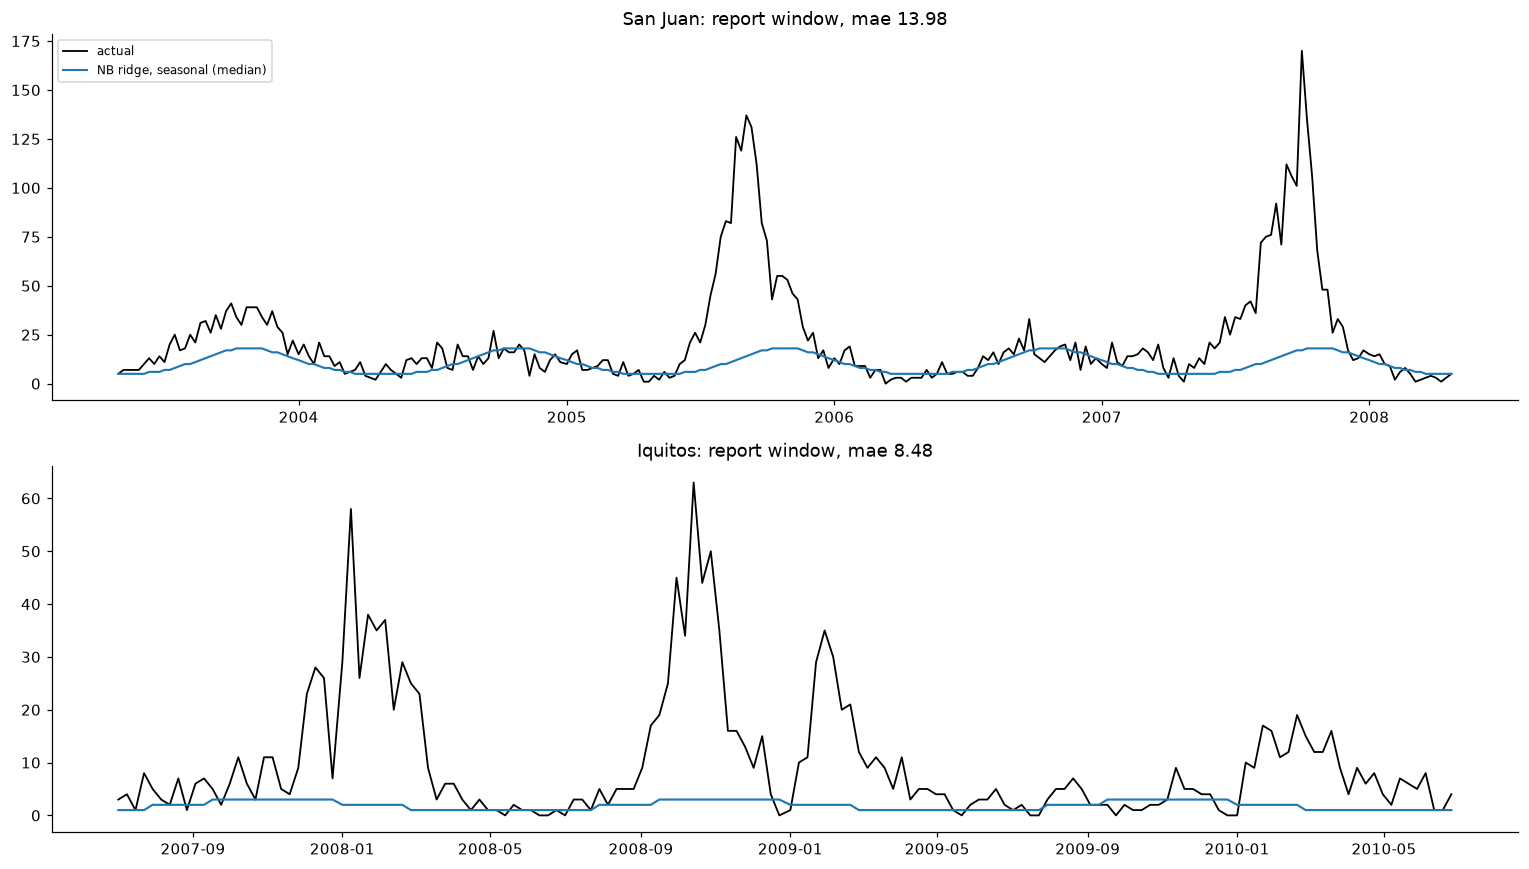

In [32]:
# ---- error by year of the forecast window (a longer horizon is harder) ----
report_pred['window_year'] = ((report_pred.weeks_ahead - 1) // 52 + 1)
by_year = report_pred.pivot_table(index='window_year', columns='city', values='abs_error', aggfunc='mean')[CITIES]
by_year.columns = [f'mae_{c}' for c in CITIES]
print('MAE by forecast year (year 1 = first 52 weeks of the report window):')
display(by_year)

# ---- forecast picture ----
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for ax, city in zip(axes, CITIES):
    part = report_pred.loc[report_pred.city.eq(city)]
    ax.plot(part.week_start_date, part[TARGET], color='k', lw=1.2, label='actual')
    ax.plot(part.week_start_date, part.pred, lw=1.4, label='NB ridge, seasonal (median)')
    ax.set_title(f'{CITY_NAMES[city]}: report window, mae {final_mae[city]:.2f}')
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'report_window_forecast.png', bbox_inches='tight'); plt.show()